In [1]:
"""
==================================================
ML LEARNING JOURNEY - DAY 103
==================================================
Week: 15 of 24
Day: 103 of 168
Date: October 30, 2026 (rebuilt - originally built May 19, 2026)
Topic: Sensor Data Processing (Camera, LiDAR, TF)
Overall Progress: 61.3%
Week 15 Progress:
✅ Day 99: ROS2 Setup & TurtleSim (COMPLETED)
✅ Day 100: ROS2 Pub/Sub & Python Nodes (COMPLETED)
✅ Day 101: ROS2 Services & Actions (COMPLETED)
✅ Day 102: ROS2 Packages, Launch & Parameters (COMPLETED)
🔄 Day 103: Sensor Data Processing (TODAY!)
⬜ Day 104: TurtleSim Controller Implementation
⬜ Day 105: TurtleSim Controller Final & Demo
Progress: 57.1% (4/7 days)
==================================================
🎯 Week 15 Project: TurtleSim Controller
- A reactive controller built on the ROS2 stack (nodes, services, launch files)
- Sensor-driven behavior: read a sensor, extract features, decide, command
- Packaged, launchable, documented and demo-ready by Day 105
🎯 Today's Learning Objectives:
1. Understand sensor_msgs/Image: header, encoding, step, raw bytes
2. Convert ROS images to NumPy/OpenCV arrays (what cv_bridge does) and detect an object
3. Understand sensor_msgs/LaserScan: angles, ranges, invalid readings (inf, NaN, out of range)
4. Build sector-based LiDAR obstacle avoidance (front / front-left / front-right)
5. Understand TF coordinate frames, homogeneous transforms and the ROS2 CLI tools
6. Apply the universal sensor pipeline pattern to the TurtleSim project design
📚 Today's Structure:
Part 1 (1.5h): Camera Data (sensor_msgs/Image, CvBridge, OpenCV)
Part 2 (1.5h): LiDAR Data (sensor_msgs/LaserScan, sector avoidance)
Part 3 (1h): TF Coordinate Frames (transforms, CLI tools)
Part 4 (1h): Universal Pattern, TurtleSim Application & Summary
🎯 SUCCESS CRITERIA:
✅ Can decode an Image message by hand and explain encoding vs step
✅ Can filter invalid LaserScan readings and compute per-sector minimum distances
✅ Can transform a point between sensor, robot and world frames with matrices
✅ Wrote camera_processor.py and lidar_processor.py ROS2 nodes (syntax verified)
✅ Simulated a sensor-driven wall-avoidance controller for the TurtleSim world
==================================================
"""

"\n==================================================\nML LEARNING JOURNEY - DAY 103\n==================================================\nWeek: 15 of 24\nDay: 103 of 168\nDate: October 30, 2026 (rebuilt - originally built May 19, 2026)\nTopic: Sensor Data Processing (Camera, LiDAR, TF)\nOverall Progress: 61.3%\nWeek 15 Progress:\n✅ Day 99: ROS2 Setup & TurtleSim (COMPLETED)\n✅ Day 100: ROS2 Pub/Sub & Python Nodes (COMPLETED)\n✅ Day 101: ROS2 Services & Actions (COMPLETED)\n✅ Day 102: ROS2 Packages, Launch & Parameters (COMPLETED)\n🔄 Day 103: Sensor Data Processing (TODAY!)\n⬜ Day 104: TurtleSim Controller Implementation\n⬜ Day 105: TurtleSim Controller Final & Demo\nProgress: 57.1% (4/7 days)\n==================================================\n🎯 Week 15 Project: TurtleSim Controller\n- A reactive controller built on the ROS2 stack (nodes, services, launch files)\n- Sensor-driven behavior: read a sensor, extract features, decide, command\n- Packaged, launchable, documented and demo-rea

In [2]:
# ==================================================
# INSTALL REQUIRED LIBRARIES
# ==================================================
# Only installs what is missing. In the ROS2 (WSL) environment numpy, OpenCV and
# matplotlib come from Ubuntu - do NOT pip-install them there (it can break cv_bridge).
import sys
import importlib.util

required = {"numpy": "numpy", "matplotlib": "matplotlib", "cv2": "opencv-python-headless"}
for mod, pkg in required.items():
    if importlib.util.find_spec(mod) is None:
        print(f"📦 Installing {pkg} ...")
        !{sys.executable} -m pip install {pkg} -q
    else:
        print(f"✅ {mod} already available")
print("✅ Libraries ready!")
print("\n" + "=" * 80)

# ==================================================
# IMPORT LIBRARIES
# ==================================================
print("\n" + "=" * 80)
print("📚 IMPORTING LIBRARIES")
print("=" * 80)

import os
import ast
import math
from dataclasses import dataclass
import numpy as np
import cv2
import matplotlib.pyplot as plt

RESULTS_DIR = "results/day103"
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
NODES_DIR = os.path.join(RESULTS_DIR, "ros_nodes")
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(NODES_DIR, exist_ok=True)

print(f"numpy {np.__version__} | opencv {cv2.__version__}")
print(f"📁 Plots folder: {PLOTS_DIR}")
print(f"📁 ROS nodes folder: {NODES_DIR}")
print("\n✅ All libraries imported successfully!")
print("=" * 80)

✅ numpy already available
✅ matplotlib already available
✅ cv2 already available
✅ Libraries ready!


📚 IMPORTING LIBRARIES


numpy 2.4.4 | opencv 4.13.0
📁 Plots folder: results/day103/plots
📁 ROS nodes folder: results/day103/ros_nodes

✅ All libraries imported successfully!


In [3]:
print("\n" + "=" * 80)
print("📚 PART 1: CAMERA DATA (sensor_msgs/Image)")
print("=" * 80)


📚 PART 1: CAMERA DATA (sensor_msgs/Image)


In [4]:
# ==================================================
# EXERCISE 1.1: THE IMAGE MESSAGE STRUCTURE
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 1.1: The sensor_msgs/Image Message")
print("=" * 80)

"""
📖 THEORY: sensor_msgs/Image
- An Image message is NOT a picture file - it is a header plus raw bytes
- Fields: header (stamp + frame_id), height, width, encoding, is_bigendian, step, data
- encoding tells you how to read the bytes (bgr8 = 3 channels, 8 bits each, blue first)
- step = number of bytes in ONE row (may be larger than width * channels because of padding)
Why this matters:
- Every camera driver publishes this message, so every vision node starts by decoding it
- Wrong encoding = swapped colors; wrong step = a sheared, garbled image
- Image topics are heavy: bandwidth planning matters on real robots
"""

@dataclass
class Header:
    stamp_sec: int
    stamp_nanosec: int
    frame_id: str

@dataclass
class ImageMsg:
    # Mirrors sensor_msgs/Image so we can learn the structure without a running ROS graph
    header: Header
    height: int
    width: int
    encoding: str
    is_bigendian: int
    step: int
    data: bytes

print("\n🛠️ Step 1: Build a synthetic 160x120 camera frame (BGR, like OpenCV)...")
H, W = 120, 160
frame = np.zeros((H, W, 3), dtype=np.uint8)
frame[:, :, 0] = np.linspace(40, 160, W).astype(np.uint8)[None, :]    # blue gradient across
frame[:, :, 1] = np.linspace(60, 100, H).astype(np.uint8)[:, None]    # green gradient down
cv2.rectangle(frame, (100, 30), (140, 80), (0, 0, 255), -1)           # RED box (target)
cv2.circle(frame, (40, 85), 14, (0, 200, 0), -1)                      # green circle (distractor)
print(f"✅ Frame created: shape={frame.shape}, dtype={frame.dtype}")

print("\n🛠️ Step 2: Pack it into an Image-style message...")
msg = ImageMsg(
    header=Header(stamp_sec=1793000000, stamp_nanosec=250_000_000, frame_id="camera_link"),
    height=H, width=W, encoding="bgr8", is_bigendian=0, step=W * 3,
    data=frame.tobytes(),
)
print(f"📊 header.frame_id : {msg.header.frame_id}")
print(f"📊 height x width  : {msg.height} x {msg.width}")
print(f"📊 encoding        : {msg.encoding}")
print(f"📊 step (bytes/row): {msg.step}  (= width {msg.width} x 3 channels)")
print(f"📊 len(data)       : {len(msg.data):,} bytes  (= step x height = {msg.step * msg.height:,})")

print("\n🛠️ Step 3: Common ROS image encodings...")
ENCODINGS = {          # name: (channels, numpy dtype)
    "mono8": (1, np.uint8),   "mono16": (1, np.uint16),
    "bgr8": (3, np.uint8),    "rgb8": (3, np.uint8),
    "bgra8": (4, np.uint8),   "rgba8": (4, np.uint8),
    "16UC1": (1, np.uint16),  "32FC1": (1, np.float32),
}
print(f"{'encoding':<8} {'channels':>8} {'dtype':>8} {'bytes/pixel':>12}")
for name, (ch, dt) in ENCODINGS.items():
    print(f"{name:<8} {ch:>8} {np.dtype(dt).name:>8} {ch * np.dtype(dt).itemsize:>12}")

print("\n🛠️ Step 4: Why image topics are heavy (bandwidth estimate)...")
for (w, h, fps) in [(160, 120, 30), (640, 480, 30), (1280, 720, 30)]:
    mb_s = w * h * 3 * fps / 1e6
    print(f"📊 {w}x{h} bgr8 @ {fps} Hz = {mb_s:7.1f} MB/s")
print("💡 Raw 720p video is ~83 MB/s - this is why image_transport and compressed topics exist.")

print("\n✅ Exercise 1.1 Complete!")
print("=" * 80)


EXERCISE 1.1: The sensor_msgs/Image Message

🛠️ Step 1: Build a synthetic 160x120 camera frame (BGR, like OpenCV)...
✅ Frame created: shape=(120, 160, 3), dtype=uint8

🛠️ Step 2: Pack it into an Image-style message...
📊 header.frame_id : camera_link
📊 height x width  : 120 x 160
📊 encoding        : bgr8
📊 step (bytes/row): 480  (= width 160 x 3 channels)
📊 len(data)       : 57,600 bytes  (= step x height = 57,600)

🛠️ Step 3: Common ROS image encodings...
encoding channels    dtype  bytes/pixel
mono8           1    uint8            1
mono16          1   uint16            2
bgr8            3    uint8            3
rgb8            3    uint8            3
bgra8           4    uint8            4
rgba8           4    uint8            4
16UC1           1   uint16            2
32FC1           1  float32            4

🛠️ Step 4: Why image topics are heavy (bandwidth estimate)...
📊 160x120 bgr8 @ 30 Hz =     1.7 MB/s
📊 640x480 bgr8 @ 30 Hz =    27.6 MB/s
📊 1280x720 bgr8 @ 30 Hz =    82.9 MB/s
💡


EXERCISE 1.2: Decode, Convert and Detect

🛠️ Step 1: Decode the message by hand and check it matches the original...
📊 decoded shape: (120, 160, 3), identical to original: True

🛠️ Step 2: Show why 'step' matters - rows padded by 8 bytes...
📊 padded step = 488, data = 58,560 bytes (vs 57,600)
📊 decoded with step: identical = True
📊 naive reshape (ignoring step): identical = False  <- the classic sheared-image bug

🛠️ Step 3: Compare with the real cv_bridge (only available inside the ROS2 environment)...
ℹ️ cv_bridge not available in this environment (ModuleNotFoundError).
ℹ️ Re-run this notebook in the ROS2 Humble kernel to see the real cv_bridge check.

🛠️ Step 4: Detect the red object with HSV thresholding...
📊 centroid = (120.0, 55.0) px
📊 bbox (x, y, w, h) = (100, 30, 41, 51)
📊 area = 2000 px^2
📊 horizontal error = +0.50  (0 = centered, + = target is to the right)


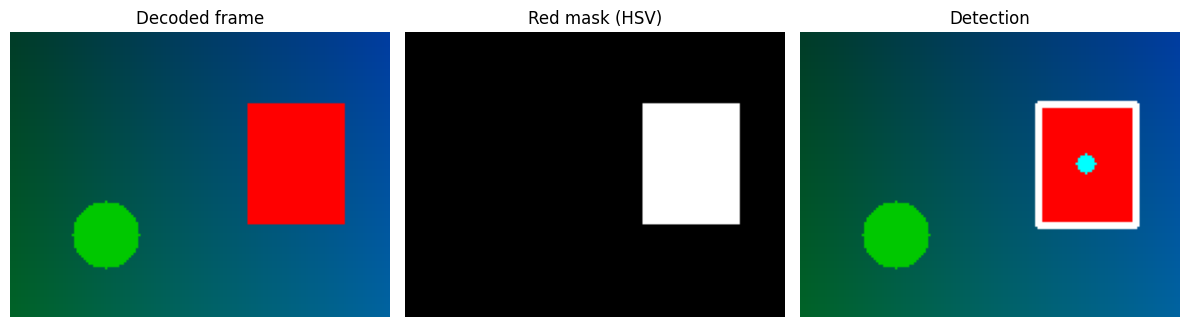

💾 Saved: results/day103/plots/01_camera_detection.png

🛠️ Step 5: Write the ROS2 camera node (runs inside a ROS2 package)...
✅ Syntax check passed (49 lines)
💾 Saved: results/day103/ros_nodes/camera_processor.py

✅ Exercise 1.2 Complete!


In [5]:
# ==================================================
# EXERCISE 1.2: DECODING IMAGES (WHAT CV_BRIDGE DOES) AND DETECTING AN OBJECT
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 1.2: Decode, Convert and Detect")
print("=" * 80)

"""
📖 THEORY: cv_bridge and OpenCV
- cv_bridge converts sensor_msgs/Image <-> NumPy arrays: imgmsg_to_cv2 / cv2_to_imgmsg
- Under the hood: np.frombuffer(data) then reshape using height, step and channels
- OpenCV uses BGR order; many ROS cameras publish rgb8 - always check msg.encoding
- Color detection is easier in HSV: hue = color, saturation = vividness, value = brightness
- Red wraps around the hue circle (0 and 180), so it needs TWO HSV ranges
Why this matters:
- A TurtleSim-style controller needs numbers (x position of a target), not pixels
- Detection -> centroid -> steering error is the basic vision-to-control chain
"""

def imgmsg_to_numpy(m):
    # Manual version of cv_bridge.imgmsg_to_cv2 (no colour conversion)
    ch, dt = ENCODINGS[m.encoding]
    itemsize = np.dtype(dt).itemsize
    flat = np.frombuffer(m.data, dtype=dt)
    per_row = m.step // itemsize                       # elements per row INCLUDING padding
    rows = flat.reshape(m.height, per_row)[:, : m.width * ch]
    return rows.reshape(m.height, m.width, ch) if ch > 1 else rows.reshape(m.height, m.width)

print("\n🛠️ Step 1: Decode the message by hand and check it matches the original...")
decoded = imgmsg_to_numpy(msg)
print(f"📊 decoded shape: {decoded.shape}, identical to original: {np.array_equal(decoded, frame)}")

print("\n🛠️ Step 2: Show why 'step' matters - rows padded by 8 bytes...")
pad = 8
padded_data = b"".join(row.tobytes() + b"\x00" * pad for row in frame)
padded_msg = ImageMsg(msg.header, H, W, "bgr8", 0, W * 3 + pad, padded_data)
decoded_padded = imgmsg_to_numpy(padded_msg)
print(f"📊 padded step = {padded_msg.step}, data = {len(padded_data):,} bytes (vs {len(msg.data):,})")
print(f"📊 decoded with step: identical = {np.array_equal(decoded_padded, frame)}")
naive = np.frombuffer(padded_data, dtype=np.uint8)[: H * W * 3].reshape(H, W, 3)
print(f"📊 naive reshape (ignoring step): identical = {np.array_equal(naive, frame)}  <- the classic sheared-image bug")

print("\n🛠️ Step 3: Compare with the real cv_bridge (only available inside the ROS2 environment)...")
try:
    from sensor_msgs.msg import Image as RosImage
    from cv_bridge import CvBridge
    bridge = CvBridge()
    ros_msg = bridge.cv2_to_imgmsg(frame, encoding="bgr8")
    back = bridge.imgmsg_to_cv2(ros_msg, desired_encoding="bgr8")
    print(f"✅ cv_bridge round trip identical: {np.array_equal(back, frame)}")
    print(f"✅ cv_bridge msg: encoding={ros_msg.encoding}, step={ros_msg.step}, "
          f"bytes={len(ros_msg.data):,}")
    print(f"✅ matches our manual decode: {np.array_equal(imgmsg_to_numpy(ImageMsg(msg.header, ros_msg.height, ros_msg.width, ros_msg.encoding, 0, ros_msg.step, bytes(ros_msg.data))), frame)}")
except Exception as e:
    print(f"ℹ️ cv_bridge not available in this environment ({type(e).__name__}).")
    print("ℹ️ Re-run this notebook in the ROS2 Humble kernel to see the real cv_bridge check.")

def detect_red_object(img_bgr, min_area=200):
    # Returns dict(centroid, bbox, area) for the largest red blob, or None
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    m1 = cv2.inRange(hsv, (0, 120, 70), (10, 255, 255))
    m2 = cv2.inRange(hsv, (170, 120, 70), (180, 255, 255))
    mask = cv2.morphologyEx(m1 | m2, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) >= min_area]
    if not contours:
        return None, mask
    c = max(contours, key=cv2.contourArea)
    mom = cv2.moments(c)
    cx, cy = mom["m10"] / mom["m00"], mom["m01"] / mom["m00"]
    return {"centroid": (cx, cy), "bbox": cv2.boundingRect(c), "area": cv2.contourArea(c)}, mask

print("\n🛠️ Step 4: Detect the red object with HSV thresholding...")
det, mask = detect_red_object(decoded)
print(f"📊 centroid = ({det['centroid'][0]:.1f}, {det['centroid'][1]:.1f}) px")
print(f"📊 bbox (x, y, w, h) = {det['bbox']}")
print(f"📊 area = {det['area']:.0f} px^2")
err = (det["centroid"][0] - W / 2) / (W / 2)
print(f"📊 horizontal error = {err:+.2f}  (0 = centered, + = target is to the right)")

annotated = decoded.copy()
x, y, bw, bh = det["bbox"]
cv2.rectangle(annotated, (x, y), (x + bw, y + bh), (255, 255, 255), 2)
cv2.circle(annotated, (int(det["centroid"][0]), int(det["centroid"][1])), 4, (255, 255, 0), -1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].imshow(cv2.cvtColor(decoded, cv2.COLOR_BGR2RGB)); axes[0].set_title("Decoded frame")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("Red mask (HSV)")
axes[2].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); axes[2].set_title("Detection")
for a in axes: a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "01_camera_detection.png"), dpi=120)
plt.show()
print(f"💾 Saved: {PLOTS_DIR}/01_camera_detection.png")

print("\n🛠️ Step 5: Write the ROS2 camera node (runs inside a ROS2 package)...")
CAMERA_NODE = """import rclpy
from rclpy.node import Node
from sensor_msgs.msg import Image
from cv_bridge import CvBridge
import cv2
import numpy as np


class CameraProcessor(Node):
    # Subscribes to a camera, finds the largest red object, publishes an annotated image.

    def __init__(self):
        super().__init__("camera_processor")
        self.bridge = CvBridge()
        self.declare_parameter("min_area", 200.0)
        self.sub = self.create_subscription(Image, "/camera/image_raw", self.on_image, 10)
        self.pub = self.create_publisher(Image, "/camera/annotated", 10)
        self.get_logger().info("camera_processor ready")

    def on_image(self, msg):
        frame = self.bridge.imgmsg_to_cv2(msg, desired_encoding="bgr8")
        hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
        m1 = cv2.inRange(hsv, (0, 120, 70), (10, 255, 255))
        m2 = cv2.inRange(hsv, (170, 120, 70), (180, 255, 255))
        mask = cv2.morphologyEx(m1 | m2, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        min_area = self.get_parameter("min_area").value
        contours = [c for c in contours if cv2.contourArea(c) >= min_area]
        if contours:
            c = max(contours, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)
            cv2.rectangle(frame, (x, y), (x + w, y + h), (255, 255, 255), 2)
            error = ((x + w / 2) - frame.shape[1] / 2) / (frame.shape[1] / 2)
            self.get_logger().info(f"target error={error:+.2f}")
        out = self.bridge.cv2_to_imgmsg(frame, encoding="bgr8")
        out.header = msg.header
        self.pub.publish(out)


def main(args=None):
    rclpy.init(args=args)
    node = CameraProcessor()
    rclpy.spin(node)
    node.destroy_node()
    rclpy.shutdown()


if __name__ == "__main__":
    main()
"""
ast.parse(CAMERA_NODE)
with open(os.path.join(NODES_DIR, "camera_processor.py"), "w") as f:
    f.write(CAMERA_NODE)
print(f"✅ Syntax check passed ({len(CAMERA_NODE.splitlines())} lines)")
print(f"💾 Saved: {NODES_DIR}/camera_processor.py")

print("\n✅ Exercise 1.2 Complete!")
print("=" * 80)

In [6]:
print("\n" + "=" * 80)
print("📊 PART 2: LIDAR DATA (sensor_msgs/LaserScan)")
print("=" * 80)


📊 PART 2: LIDAR DATA (sensor_msgs/LaserScan)



EXERCISE 2.1: The sensor_msgs/LaserScan Message

🛠️ Step 1: Build a scan with a front obstacle (0.55 m) and a left obstacle (1.0 m)...
📊 readings: 360
📊 angle_min=0.00, angle_max=6.28, increment=1.0 deg
📊 valid range window: 0.12 m to 3.5 m

🛠️ Step 2: Classify the readings...
📊 inf readings       : 7
📊 below range_min    : 2   <- garbage readings very close to the sensor
📊 above range_max    : 0
📊 valid after filter : 351 of 360
📊 closest valid obstacle: 0.53 m at +6 deg

🛠️ Step 3: Convert polar readings to x/y points (robot frame, x forward, y left)...


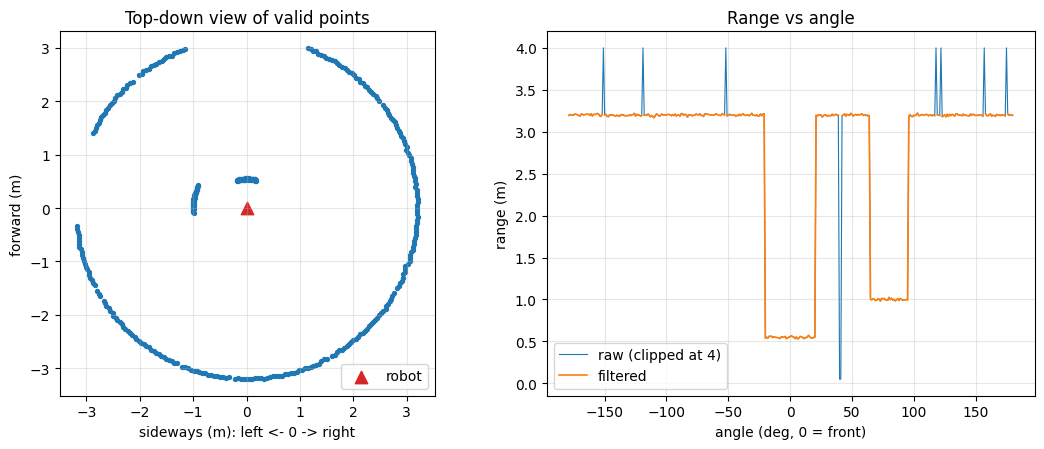

💾 Saved: results/day103/plots/02_laserscan_overview.png

✅ Exercise 2.1 Complete!


In [7]:
# ==================================================
# EXERCISE 2.1: THE LASERSCAN MESSAGE
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 2.1: The sensor_msgs/LaserScan Message")
print("=" * 80)

"""
📖 THEORY: sensor_msgs/LaserScan
- A 2D LiDAR spins and reports one distance per angle
- Fields: angle_min, angle_max, angle_increment, range_min, range_max, ranges[]
- Angle of reading i = angle_min + i * angle_increment (radians, 0 = straight ahead, + = left)
- TurtleBot3 LDS-01: 360 readings, 0.12 m to 3.5 m, angles 0 to 2*pi
- Invalid readings are normal: inf (nothing hit), NaN, or outside [range_min, range_max]
Why this matters:
- Using raw ranges without filtering makes robots stop for ghosts or drive into walls
- Every avoidance and mapping algorithm starts with this cleaning step
"""

@dataclass
class LaserScanMsg:
    angle_min: float
    angle_max: float
    angle_increment: float
    range_min: float
    range_max: float
    ranges: np.ndarray

def wrap_pi(a):
    # Wrap angles to [-pi, pi) so that "front" is around 0 and left is positive
    return np.arctan2(np.sin(a), np.cos(a))

def make_scan(obstacles, seed=7, far_wall=3.2, noise=0.01, dropout=0.03):
    # Synthetic LDS-01 style scan. obstacles = [(center_deg, half_width_deg, distance_m), ...]
    rng = np.random.default_rng(seed)
    n = 360
    deg = np.arange(n)                                       # 0..359 like the real LDS-01
    signed = ((deg + 180) % 360) - 180                       # -180..179, 0 = front
    ranges = np.full(n, far_wall) + rng.normal(0, noise, n)
    for center, half, dist in obstacles:
        diff = ((signed - center + 180) % 360) - 180
        hit = np.abs(diff) <= half
        ranges[hit] = dist + rng.normal(0, noise, hit.sum())
    ranges[rng.random(n) < dropout] = np.inf                 # random dropouts
    ranges[[40, 41]] = 0.05                                  # too-close garbage readings
    return LaserScanMsg(0.0, 2 * math.pi, 2 * math.pi / n, 0.12, 3.5, ranges)

def scan_angles(scan):
    return wrap_pi(scan.angle_min + np.arange(len(scan.ranges)) * scan.angle_increment)

def valid_ranges(scan):
    r = scan.ranges.astype(float).copy()
    bad = ~np.isfinite(r) | (r < scan.range_min) | (r > scan.range_max)
    r[bad] = np.nan
    return r

print("\n🛠️ Step 1: Build a scan with a front obstacle (0.55 m) and a left obstacle (1.0 m)...")
scan = make_scan([(0, 20, 0.55), (80, 15, 1.0)])
print(f"📊 readings: {len(scan.ranges)}")
print(f"📊 angle_min={scan.angle_min:.2f}, angle_max={scan.angle_max:.2f}, "
      f"increment={math.degrees(scan.angle_increment):.1f} deg")
print(f"📊 valid range window: {scan.range_min} m to {scan.range_max} m")

print("\n🛠️ Step 2: Classify the readings...")
n_inf = int(np.sum(~np.isfinite(scan.ranges)))
n_low = int(np.sum(np.isfinite(scan.ranges) & (scan.ranges < scan.range_min)))
n_high = int(np.sum(np.isfinite(scan.ranges) & (scan.ranges > scan.range_max)))
clean = valid_ranges(scan)
print(f"📊 inf readings       : {n_inf}")
print(f"📊 below range_min    : {n_low}   <- garbage readings very close to the sensor")
print(f"📊 above range_max    : {n_high}")
print(f"📊 valid after filter : {int(np.sum(np.isfinite(clean)))} of {len(scan.ranges)}")
print(f"📊 closest valid obstacle: {np.nanmin(clean):.2f} m "
      f"at {math.degrees(scan_angles(scan)[np.nanargmin(clean)]):+.0f} deg")

print("\n🛠️ Step 3: Convert polar readings to x/y points (robot frame, x forward, y left)...")
ang = scan_angles(scan)
xs, ys = clean * np.cos(ang), clean * np.sin(ang)
ok = np.isfinite(xs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].scatter(-ys[ok], xs[ok], s=8, c="tab:blue")
axes[0].scatter([0], [0], s=80, c="tab:red", marker="^", label="robot")
axes[0].set_aspect("equal"); axes[0].grid(alpha=0.3); axes[0].legend(loc="lower right")
axes[0].set_xlabel("sideways (m): left <- 0 -> right"); axes[0].set_ylabel("forward (m)")
axes[0].set_title("Top-down view of valid points")
axes[1].plot(np.degrees(ang[np.argsort(ang)]), scan.ranges[np.argsort(ang)].clip(max=4), lw=0.8, label="raw (clipped at 4)")
axes[1].plot(np.degrees(ang[np.argsort(ang)]), clean[np.argsort(ang)], lw=1.2, label="filtered")
axes[1].set_xlabel("angle (deg, 0 = front)"); axes[1].set_ylabel("range (m)")
axes[1].set_title("Range vs angle"); axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "02_laserscan_overview.png"), dpi=120)
plt.show()
print(f"💾 Saved: {PLOTS_DIR}/02_laserscan_overview.png")

print("\n✅ Exercise 2.1 Complete!")
print("=" * 80)


EXERCISE 2.2: Sector-Based Obstacle Avoidance

🛠️ Step 1: Sector distances for the scan from Exercise 2.1...
📊 front       :  0.53 m
📊 front_left  :  0.98 m
📊 front_right :  3.17 m
📊 back_left   :  0.99 m
📊 back_right  :  3.17 m
🤖 Decision: SLOW -> v=0.02 m/s, w=-0.50 rad/s

🛠️ Step 2: Test five scenarios...
scenario                          front  f-left  f-right  state            v      w
Open corridor                      3.17    3.17     3.18  CRUISE        0.22  +0.00
Obstacle ahead, left blocked       0.37    0.43     3.18  AVOID         0.03  -1.00
Obstacle ahead, right blocked      0.37    3.17     0.43  AVOID         0.03  +1.00
Wall very close                    0.17    3.17     3.18  BLOCKED       0.00  -1.00
Obstacle on left only              3.17    0.37     3.18  NUDGE_RIGHT   0.22  -0.50


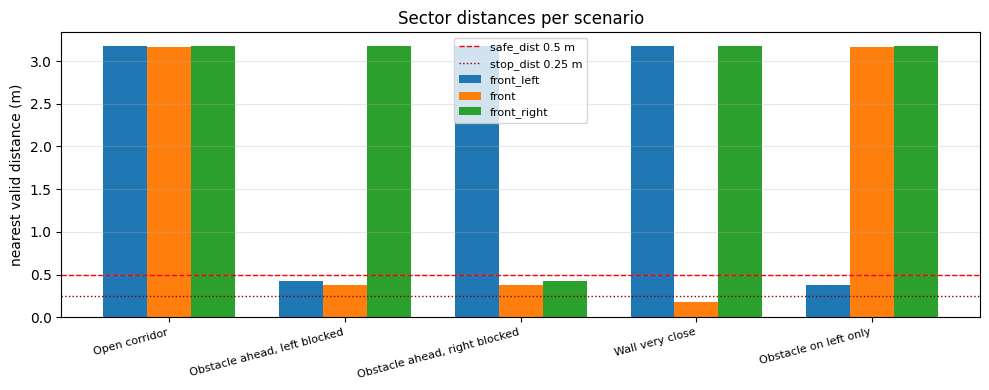

💾 Saved: results/day103/plots/03_sector_scenarios.png

🛠️ Step 3: Write the ROS2 LiDAR node...
✅ Syntax check passed (75 lines)
💾 Saved: results/day103/ros_nodes/lidar_processor.py

✅ Exercise 2.2 Complete!


In [8]:
# ==================================================
# EXERCISE 2.2: SECTOR-BASED OBSTACLE AVOIDANCE
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 2.2: Sector-Based Obstacle Avoidance")
print("=" * 80)

"""
📖 THEORY: Sector-based avoidance
- Split the scan into sectors (front, front-left, front-right ...)
- Take the minimum VALID distance in each sector: "how close is the nearest thing there?"
- Decide from a few numbers instead of 360: cruise, slow, turn toward the open side, or stop
- Behavior has thresholds: stop_dist < safe_dist < slow_dist
Why this matters:
- It is cheap, robust and works with any range sensor (LiDAR, ultrasonic, TurtleSim walls)
- It is the first reactive behavior used in the Day 110 patrol robot
"""

SECTORS = {                      # degrees, 0 = front, + = left
    "front": (-30, 30), "front_left": (30, 90), "front_right": (-90, -30),
    "back_left": (90, 180), "back_right": (-180, -90),
}

def sector_distances(ranges, angles_rad):
    # ranges may contain NaN; returns {sector: min valid distance or inf}
    deg = np.degrees(angles_rad)
    out = {}
    for name, (lo, hi) in SECTORS.items():
        vals = ranges[(deg >= lo) & (deg < hi)]
        vals = vals[np.isfinite(vals)]
        out[name] = float(vals.min()) if vals.size else float("inf")
    return out

def decide(sectors, stop_dist=0.25, safe_dist=0.5, slow_dist=0.9, v_max=0.22, w_max=1.0):
    # Returns dict(state, v, w). v = forward m/s, w = turn rad/s (+ = turn left)
    f, fl, fr = sectors["front"], sectors["front_left"], sectors["front_right"]
    turn_dir = 1.0 if fl >= fr else -1.0                    # turn toward the more open side
    if min(f, fl, fr) < stop_dist:
        return {"state": "BLOCKED", "v": 0.0, "w": turn_dir * w_max}
    if f < safe_dist:
        return {"state": "AVOID", "v": 0.03, "w": turn_dir * w_max}
    if f < slow_dist:
        v = v_max * (f - safe_dist) / (slow_dist - safe_dist)
        return {"state": "SLOW", "v": v, "w": turn_dir * 0.5 * w_max}
    if fl < safe_dist:
        return {"state": "NUDGE_RIGHT", "v": v_max, "w": -0.5 * w_max}
    if fr < safe_dist:
        return {"state": "NUDGE_LEFT", "v": v_max, "w": 0.5 * w_max}
    return {"state": "CRUISE", "v": v_max, "w": 0.0}

print("\n🛠️ Step 1: Sector distances for the scan from Exercise 2.1...")
sectors = sector_distances(valid_ranges(scan), scan_angles(scan))
for name, d in sectors.items():
    print(f"📊 {name:<12}: {d:5.2f} m")
cmd = decide(sectors)
print(f"🤖 Decision: {cmd['state']} -> v={cmd['v']:.2f} m/s, w={cmd['w']:+.2f} rad/s")

print("\n🛠️ Step 2: Test five scenarios...")
scenarios = {
    "Open corridor":        [],
    "Obstacle ahead, left blocked":  [(0, 20, 0.40), (60, 25, 0.45)],
    "Obstacle ahead, right blocked": [(0, 20, 0.40), (-60, 25, 0.45)],
    "Wall very close":      [(0, 25, 0.20)],
    "Obstacle on left only": [(55, 12, 0.40)],
}
print(f"{'scenario':<32} {'front':>6} {'f-left':>7} {'f-right':>8}  {'state':<12} {'v':>5} {'w':>6}")
results = []
for name, obs in scenarios.items():
    s = make_scan(obs, seed=3, dropout=0.02)
    sec = sector_distances(valid_ranges(s), scan_angles(s))
    c = decide(sec)
    results.append((name, sec, c))
    print(f"{name:<32} {sec['front']:>6.2f} {sec['front_left']:>7.2f} {sec['front_right']:>8.2f}  "
          f"{c['state']:<12} {c['v']:>5.2f} {c['w']:>+6.2f}")

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.25
xs_ = np.arange(len(results))
for i, key in enumerate(["front_left", "front", "front_right"]):
    ax.bar(xs_ + (i - 1) * width, [min(r[1][key], 3.5) for r in results], width, label=key)
ax.axhline(0.5, color="red", ls="--", lw=1, label="safe_dist 0.5 m")
ax.axhline(0.25, color="darkred", ls=":", lw=1, label="stop_dist 0.25 m")
ax.set_xticks(xs_); ax.set_xticklabels([r[0] for r in results], rotation=15, ha="right", fontsize=8)
ax.set_ylabel("nearest valid distance (m)"); ax.set_title("Sector distances per scenario")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "03_sector_scenarios.png"), dpi=120)
plt.show()
print(f"💾 Saved: {PLOTS_DIR}/03_sector_scenarios.png")

print("\n🛠️ Step 3: Write the ROS2 LiDAR node...")
LIDAR_NODE = """import math
import numpy as np
import rclpy
from rclpy.node import Node
from rclpy.qos import qos_profile_sensor_data
from sensor_msgs.msg import LaserScan
from geometry_msgs.msg import Twist

SECTORS = {
    "front": (-30, 30),
    "front_left": (30, 90),
    "front_right": (-90, -30),
}


class LidarProcessor(Node):
    # Sector-based obstacle avoidance: /scan in, /cmd_vel out.

    def __init__(self):
        super().__init__("lidar_processor")
        self.declare_parameter("stop_dist", 0.25)
        self.declare_parameter("safe_dist", 0.5)
        self.declare_parameter("slow_dist", 0.9)
        self.declare_parameter("v_max", 0.22)
        self.declare_parameter("w_max", 1.0)
        self.sub = self.create_subscription(LaserScan, "/scan", self.on_scan, qos_profile_sensor_data)
        self.pub = self.create_publisher(Twist, "/cmd_vel", 10)
        self.get_logger().info("lidar_processor ready")

    def sector_min(self, scan):
        ranges = np.array(scan.ranges, dtype=float)
        angles = scan.angle_min + np.arange(len(ranges)) * scan.angle_increment
        angles = np.degrees(np.arctan2(np.sin(angles), np.cos(angles)))
        bad = ~np.isfinite(ranges) | (ranges < scan.range_min) | (ranges > scan.range_max)
        ranges[bad] = np.nan
        out = {}
        for name, (lo, hi) in SECTORS.items():
            vals = ranges[(angles >= lo) & (angles < hi)]
            vals = vals[np.isfinite(vals)]
            out[name] = float(vals.min()) if vals.size else float("inf")
        return out

    def on_scan(self, scan):
        s = self.sector_min(scan)
        p = {k: self.get_parameter(k).value for k in ("stop_dist", "safe_dist", "slow_dist", "v_max", "w_max")}
        f, fl, fr = s["front"], s["front_left"], s["front_right"]
        turn = 1.0 if fl >= fr else -1.0
        cmd = Twist()
        if min(f, fl, fr) < p["stop_dist"]:
            cmd.angular.z = turn * p["w_max"]
        elif f < p["safe_dist"]:
            cmd.linear.x = 0.03
            cmd.angular.z = turn * p["w_max"]
        elif f < p["slow_dist"]:
            cmd.linear.x = p["v_max"] * (f - p["safe_dist"]) / (p["slow_dist"] - p["safe_dist"])
            cmd.angular.z = turn * 0.5 * p["w_max"]
        else:
            cmd.linear.x = p["v_max"]
            if fl < p["safe_dist"]:
                cmd.angular.z = -0.5 * p["w_max"]
            elif fr < p["safe_dist"]:
                cmd.angular.z = 0.5 * p["w_max"]
        self.pub.publish(cmd)


def main(args=None):
    rclpy.init(args=args)
    node = LidarProcessor()
    rclpy.spin(node)
    node.destroy_node()
    rclpy.shutdown()


if __name__ == "__main__":
    main()
"""
ast.parse(LIDAR_NODE)
with open(os.path.join(NODES_DIR, "lidar_processor.py"), "w") as f:
    f.write(LIDAR_NODE)
print(f"✅ Syntax check passed ({len(LIDAR_NODE.splitlines())} lines)")
print(f"💾 Saved: {NODES_DIR}/lidar_processor.py")

print("\n✅ Exercise 2.2 Complete!")
print("=" * 80)

In [9]:
print("\n" + "=" * 80)
print("📊 PART 3: TF COORDINATE FRAMES")
print("=" * 80)


📊 PART 3: TF COORDINATE FRAMES



EXERCISE 3.1: Frames and Homogeneous Transforms

🛠️ Step 1: Define the frames (TurtleBot3 Burger geometry)...
T_base_scan (LiDAR in robot body):
 [[ 1.    -0.    -0.032]
 [ 0.     1.     0.   ]
 [ 0.     0.     1.   ]]
T_odom_base (robot in odometry frame):
 [[ 0.866 -0.5    2.   ]
 [ 0.5    0.866  1.   ]
 [ 0.     0.     1.   ]]

🛠️ Step 2: Transform ONE obstacle point: 0.55 m straight ahead of the LiDAR...
📊 in base_scan frame: (0.550, 0.000)
📊 in base_link frame: (0.518, 0.000)
📊 in odom frame     : (2.449, 1.259)

🛠️ Step 3: Chain the transforms and verify the maths...
📊 chained result identical: True
📊 inverse returns the original point: True
📊 hand calculation matches: True

🛠️ Step 4: Transform the WHOLE scan into the odom frame and plot the frames...


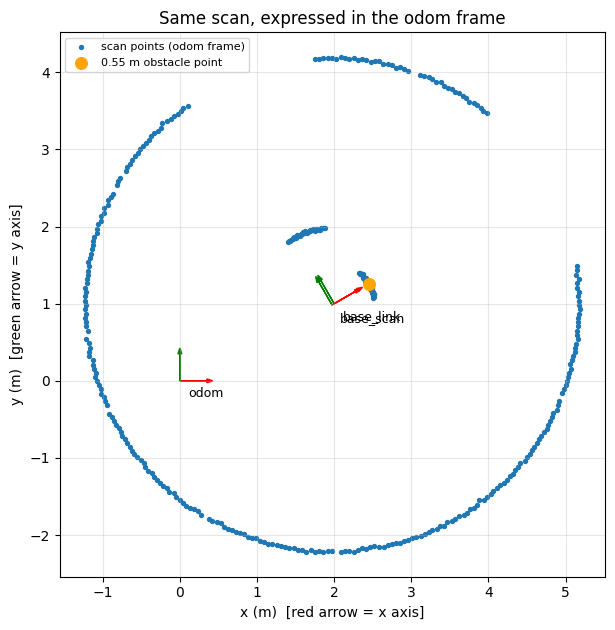

💾 Saved: results/day103/plots/04_frames_and_scan.png

✅ Exercise 3.1 Complete!


In [10]:
# ==================================================
# EXERCISE 3.1: TRANSFORMING POINTS BETWEEN FRAMES
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 3.1: Frames and Homogeneous Transforms")
print("=" * 80)

"""
📖 THEORY: Coordinate frames
- Every sensor measures in ITS OWN frame: LiDAR in base_scan, camera in camera_link
- The robot body is base_link; the odometry origin is odom; the map origin is map
- A 2D pose (x, y, yaw) becomes a 3x3 homogeneous matrix T so transforms can be chained
- T_a_b maps coordinates from frame b into frame a;  T_a_c = T_a_b @ T_b_c
Why this matters:
- "Obstacle 0.55 m ahead of the LiDAR" is useless for navigation until it is expressed in odom/map
- TF is how ROS2 keeps this bookkeeping for the whole robot
"""

def T2D(x, y, yaw):
    c, s = math.cos(yaw), math.sin(yaw)
    return np.array([[c, -s, x], [s, c, y], [0.0, 0.0, 1.0]])

print("\n🛠️ Step 1: Define the frames (TurtleBot3 Burger geometry)...")
T_base_scan = T2D(-0.032, 0.0, 0.0)                 # LiDAR sits 3.2 cm behind base_link centre
T_odom_base = T2D(2.0, 1.0, math.radians(30))       # robot at (2, 1) m, rotated 30 degrees
print("T_base_scan (LiDAR in robot body):\n", np.round(T_base_scan, 3))
print("T_odom_base (robot in odometry frame):\n", np.round(T_odom_base, 3))

print("\n🛠️ Step 2: Transform ONE obstacle point: 0.55 m straight ahead of the LiDAR...")
p_scan = np.array([0.55, 0.0, 1.0])
p_base = T_base_scan @ p_scan
p_odom = T_odom_base @ p_base
print(f"📊 in base_scan frame: ({p_scan[0]:.3f}, {p_scan[1]:.3f})")
print(f"📊 in base_link frame: ({p_base[0]:.3f}, {p_base[1]:.3f})")
print(f"📊 in odom frame     : ({p_odom[0]:.3f}, {p_odom[1]:.3f})")

print("\n🛠️ Step 3: Chain the transforms and verify the maths...")
T_odom_scan = T_odom_base @ T_base_scan
print(f"📊 chained result identical: {np.allclose(T_odom_scan @ p_scan, p_odom)}")
back = np.linalg.inv(T_odom_scan) @ p_odom
print(f"📊 inverse returns the original point: {np.allclose(back, p_scan)}")
expected = np.array([2.0 + (0.55 - 0.032) * math.cos(math.radians(30)),
                     1.0 + (0.55 - 0.032) * math.sin(math.radians(30))])
print(f"📊 hand calculation matches: {np.allclose(p_odom[:2], expected)}")

print("\n🛠️ Step 4: Transform the WHOLE scan into the odom frame and plot the frames...")
clean = valid_ranges(scan)
ang = scan_angles(scan)
pts_scan = np.vstack([clean * np.cos(ang), clean * np.sin(ang), np.ones_like(clean)])
ok = np.isfinite(pts_scan[0])
pts_odom = T_odom_scan @ pts_scan[:, ok]

def draw_frame(ax, T, name, length=0.35):
    o = T[:2, 2]
    ax.arrow(o[0], o[1], T[0, 0] * length, T[1, 0] * length, color="red", head_width=0.05)
    ax.arrow(o[0], o[1], T[0, 1] * length, T[1, 1] * length, color="green", head_width=0.05)
    ax.annotate(name, o, textcoords="offset points", xytext=(6, -12), fontsize=9)

fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.scatter(pts_odom[0], pts_odom[1], s=8, c="tab:blue", label="scan points (odom frame)")
draw_frame(ax, np.eye(3), "odom"); draw_frame(ax, T_odom_base, "base_link"); draw_frame(ax, T_odom_scan, "base_scan")
ax.scatter(*p_odom[:2], s=70, c="orange", zorder=5, label="0.55 m obstacle point")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
ax.set_xlabel("x (m)  [red arrow = x axis]"); ax.set_ylabel("y (m)  [green arrow = y axis]")
ax.set_title("Same scan, expressed in the odom frame")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "04_frames_and_scan.png"), dpi=120)
plt.show()
print(f"💾 Saved: {PLOTS_DIR}/04_frames_and_scan.png")

print("\n✅ Exercise 3.1 Complete!")
print("=" * 80)

In [11]:
# ==================================================
# EXERCISE 3.2: THE TF TREE AND ROS2 CLI TOOLS
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 3.2: TF Tree and CLI Tools")
print("=" * 80)

"""
📖 THEORY: The TF tree
- Frames form a TREE: each frame has exactly one parent
- Typical mobile robot: map -> odom -> base_footprint -> base_link -> base_scan / camera_link
- /tf carries moving transforms (odometry), /tf_static carries fixed ones (sensor mounts)
- A lookup between any two frames walks up to their common ancestor and back down
Why this matters:
- You almost never compute transforms by hand: tf2 does it for you (lookup_transform)
- Broken trees (missing parent, two roots) are one of the most common ROS2 debugging issues
"""

class TinyTF:
    # Minimal tf2-style buffer: parent map + transform T_parent_child for every child
    def __init__(self):
        self.parent, self.T = {}, {}

    def add(self, parent, child, T_parent_child):
        self.parent[child], self.T[child] = parent, T_parent_child

    def _to_root(self, frame):
        acc = np.eye(3)
        while frame in self.parent:
            acc = self.T[frame] @ acc
            frame = self.parent[frame]
        return frame, acc                                   # root name, T_root_frame

    def lookup(self, target, source):
        # T_target_source: express source-frame coordinates in the target frame
        root_t, T_rt = self._to_root(target)
        root_s, T_rs = self._to_root(source)
        if root_t != root_s:
            raise ValueError(f"frames are in different trees: {root_t} vs {root_s}")
        return np.linalg.inv(T_rt) @ T_rs

print("\n🛠️ Step 1: Build a TurtleBot3-like tree...")
tf = TinyTF()
tf.add("map", "odom", T2D(0.5, -0.2, math.radians(5)))
tf.add("odom", "base_footprint", T2D(2.0, 1.0, math.radians(30)))
tf.add("base_footprint", "base_link", T2D(0.0, 0.0, 0.0))
tf.add("base_link", "base_scan", T2D(-0.032, 0.0, 0.0))
tf.add("base_link", "camera_link", T2D(0.06, 0.0, 0.0))
print("map\n└── odom\n    └── base_footprint\n        └── base_link\n            ├── base_scan\n            └── camera_link")

print("\n🛠️ Step 2: Look up transforms between any two frames...")
for target, source in [("odom", "base_scan"), ("map", "camera_link"), ("camera_link", "base_scan")]:
    T = tf.lookup(target, source)
    x, y = T[0, 2], T[1, 2]
    yaw = math.degrees(math.atan2(T[1, 0], T[0, 0]))
    print(f"📊 {target:<12} <- {source:<12}: x={x:+.3f} m, y={y:+.3f} m, yaw={yaw:+.1f} deg")

print("\n🛠️ Step 3: Check the maths and the error case...")
print(f"📊 odom<-base_scan equals Exercise 3.1 result: {np.allclose(tf.lookup('odom', 'base_scan'), T_odom_scan)}")
a = tf.lookup("camera_link", "base_scan")
b = np.linalg.inv(tf.lookup("base_scan", "camera_link"))
print(f"📊 lookup(a,b) == inverse(lookup(b,a)): {np.allclose(a, b)}")
try:
    tf.lookup("map", "ghost_frame")
    print("📊 unknown frame treated as its own root (no error raised)")
except ValueError as e:
    print(f"✅ Different trees correctly rejected: {e}")

print("\n🛠️ Step 4: ROS2 CLI cheat sheet for TF (run these in the ROS2 terminal)...")
cheat = [
    ("ros2 run tf2_tools view_frames",
     "Listen ~5 s and save the whole tree as frames_<time>.pdf"),
    ("ros2 run tf2_ros tf2_echo odom base_link",
     "Print the live transform odom -> base_link"),
    ("ros2 topic echo /tf_static --once",
     "Show fixed (static) transforms such as sensor mounts"),
    ("ros2 topic echo /tf --once",
     "Show one batch of moving transforms"),
    ("ros2 run tf2_ros static_transform_publisher --x -0.032 --y 0 --z 0.172 --yaw 0 --pitch 0 --roll 0 --frame-id base_link --child-frame-id base_scan",
     "Publish a fixed mount (Humble flag syntax)"),
]
for cmd_, what in cheat:
    print(f"$ {cmd_}\n    -> {what}")

print("\n✅ Exercise 3.2 Complete!")
print("=" * 80)


EXERCISE 3.2: TF Tree and CLI Tools

🛠️ Step 1: Build a TurtleBot3-like tree...
map
└── odom
    └── base_footprint
        └── base_link
            ├── base_scan
            └── camera_link

🛠️ Step 2: Look up transforms between any two frames...
📊 odom         <- base_scan   : x=+1.972 m, y=+0.984 m, yaw=+30.0 deg
📊 map          <- camera_link : x=+2.454 m, y=+1.005 m, yaw=+35.0 deg
📊 camera_link  <- base_scan   : x=-0.092 m, y=-0.000 m, yaw=-0.0 deg

🛠️ Step 3: Check the maths and the error case...
📊 odom<-base_scan equals Exercise 3.1 result: True
📊 lookup(a,b) == inverse(lookup(b,a)): True
✅ Different trees correctly rejected: frames are in different trees: map vs ghost_frame

🛠️ Step 4: ROS2 CLI cheat sheet for TF (run these in the ROS2 terminal)...
$ ros2 run tf2_tools view_frames
    -> Listen ~5 s and save the whole tree as frames_<time>.pdf
$ ros2 run tf2_ros tf2_echo odom base_link
    -> Print the live transform odom -> base_link
$ ros2 topic echo /tf_static --once
    ->

In [12]:
print("\n" + "=" * 80)
print("📊 PART 4: UNIVERSAL PATTERN & TURTLESIM APPLICATION")
print("=" * 80)


📊 PART 4: UNIVERSAL PATTERN & TURTLESIM APPLICATION


In [13]:
# ==================================================
# EXERCISE 4.1: THE UNIVERSAL SENSOR PROCESSING PATTERN
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 4.1: One Pattern for Every Sensor")
print("=" * 80)

"""
📖 THEORY: Universal sensor processing pattern
- 1. Subscribe  : receive the raw message
- 2. Convert    : bytes/arrays -> NumPy
- 3. Validate   : remove invalid data (NaN, inf, out of range, empty frames)
- 4. Extract    : turn data into a few meaningful numbers (centroid, sector minimum)
- 5. Decide     : thresholds / control law -> a command
- 6. Publish    : send Twist, markers or diagnostics
Why this matters:
- Camera, LiDAR, IMU, odometry - the code differs, the structure does not
- The TurtleSim controller (Days 104-105) is built from exactly these stages
"""

class SensorPipeline:
    def __init__(self, name, stages):
        self.name, self.stages = name, stages

    def run(self, raw):
        data, trace = raw, []
        for stage_name, fn in self.stages:
            data = fn(data)
            trace.append(stage_name)
        return data, trace

def steer_to_target(det, width=W, k=0.8, v=0.15):
    if det is None:
        return {"state": "SEARCH", "v": 0.0, "w": 0.4}
    err = (det["centroid"][0] - width / 2) / (width / 2)
    return {"state": "TRACK", "v": v, "w": -k * err}        # target on the right -> turn right (negative)

camera_pipeline = SensorPipeline("camera", [
    ("convert",  imgmsg_to_numpy),
    ("extract",  lambda img: detect_red_object(img)[0]),
    ("decide",   steer_to_target),
])
lidar_pipeline = SensorPipeline("lidar", [
    ("validate", lambda s: (s, valid_ranges(s))),
    ("extract",  lambda t: sector_distances(t[1], scan_angles(t[0]))),
    ("decide",   decide),
])

print("\n🛠️ Step 1: Run both pipelines...")
cam_cmd, cam_trace = camera_pipeline.run(msg)
lid_cmd, lid_trace = lidar_pipeline.run(scan)
print(f"📷 camera stages: {' -> '.join(cam_trace)}")
print(f"   command: {cam_cmd['state']}, v={cam_cmd['v']:.2f}, w={cam_cmd['w']:+.2f}  (red box is right of centre -> turn right)")
print(f"📡 lidar stages : {' -> '.join(lid_trace)}")
print(f"   command: {lid_cmd['state']}, v={lid_cmd['v']:.2f}, w={lid_cmd['w']:+.2f}")

print("\n🛠️ Step 2: Edge cases - the 'validate' stage is what keeps robots safe...")
blank = ImageMsg(msg.header, H, W, "bgr8", 0, W * 3, np.zeros((H, W, 3), np.uint8).tobytes())
print(f"📷 blank frame  -> {camera_pipeline.run(blank)[0]['state']} (no target: rotate and search)")
empty_scan = LaserScanMsg(0.0, 2 * math.pi, 2 * math.pi / 360, 0.12, 3.5, np.full(360, np.inf))
print(f"📡 all-inf scan -> {lidar_pipeline.run(empty_scan)[0]['state']} (nothing detected: cruise)")
print("💡 Production robots also add a watchdog: if no scan arrives for 0.5 s, publish a zero Twist.")

print("\n✅ Exercise 4.1 Complete!")
print("=" * 80)


EXERCISE 4.1: One Pattern for Every Sensor

🛠️ Step 1: Run both pipelines...
📷 camera stages: convert -> extract -> decide
   command: TRACK, v=0.15, w=-0.40  (red box is right of centre -> turn right)
📡 lidar stages : validate -> extract -> decide
   command: SLOW, v=0.02, w=-0.50

🛠️ Step 2: Edge cases - the 'validate' stage is what keeps robots safe...
📷 blank frame  -> SEARCH (no target: rotate and search)
📡 all-inf scan -> CRUISE (nothing detected: cruise)
💡 Production robots also add a watchdog: if no scan arrives for 0.5 s, publish a zero Twist.

✅ Exercise 4.1 Complete!



EXERCISE 4.2: Virtual Rangefinder for the TurtleSim World

🛠️ Step 1: Test the virtual rangefinder at the centre of the world...
📊 beams: 36, front beam range = 5.54 (expected 5.54)

🛠️ Step 2: Simulate 60 s of driving with the sector controller...
📊 steps: 1200 (60 s simulated)
📊 distance travelled: 101.3 units
📊 minimum wall clearance: 1.48 units (must stay > 0)
📊 stayed inside the world: True
📊 state CRUISE      :  745 steps (62.1%)
📊 state NUDGE_LEFT  :   49 steps ( 4.1%)
📊 state SLOW        :  406 steps (33.8%)


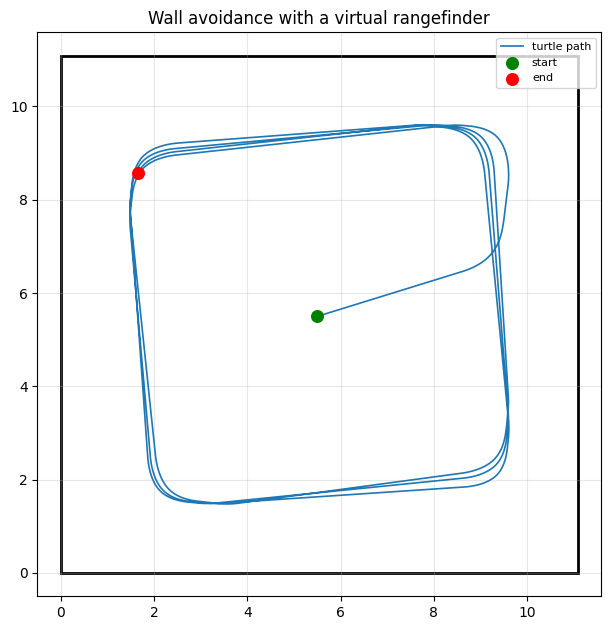

💾 Saved: results/day103/plots/05_turtlesim_wall_avoidance.png

✅ Exercise 4.2 Complete!


In [14]:
# ==================================================
# EXERCISE 4.2: TURTLESIM SENSOR-DRIVEN WALL AVOIDANCE (SIMULATION)
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 4.2: Virtual Rangefinder for the TurtleSim World")
print("=" * 80)

"""
📖 THEORY: Giving TurtleSim a sensor
- TurtleSim has NO LiDAR: it only publishes /turtle1/pose (x, y, theta)
- We can build a VIRTUAL rangefinder: cast rays from the pose to the walls of the 11 x 11 world
- The result is a LaserScan-like array, so the SAME sector logic from Exercise 2.2 applies
- Reactive loop: pose -> virtual scan -> sectors -> decide -> /turtle1/cmd_vel
Why this matters:
- This is the design for the Day 104 controller: sensor-style code, tested in simulation first
- Nothing here needs ROS - the logic is verified before it is wrapped in a node
"""

WORLD = 11.0889                                              # TurtleSim world size (units)

def ray_to_wall(x, y, phi):
    dx, dy = math.cos(phi), math.sin(phi)
    ts = []
    if dx > 1e-9:  ts.append((WORLD - x) / dx)
    if dx < -1e-9: ts.append((0.0 - x) / dx)
    if dy > 1e-9:  ts.append((WORLD - y) / dy)
    if dy < -1e-9: ts.append((0.0 - y) / dy)
    return min(t for t in ts if t >= 0)

def virtual_scan(x, y, theta, n_beams=36, max_range=8.0):
    rel = -math.pi + np.arange(n_beams) * (2 * math.pi / n_beams)    # -180..+170 deg relative to heading
    ranges = np.array([min(ray_to_wall(x, y, theta + a), max_range) for a in rel])
    return LaserScanMsg(-math.pi, math.pi, 2 * math.pi / n_beams, 0.05, max_range, ranges)

print("\n🛠️ Step 1: Test the virtual rangefinder at the centre of the world...")
test = virtual_scan(WORLD / 2, WORLD / 2, 0.0)
print(f"📊 beams: {len(test.ranges)}, front beam range = {test.ranges[len(test.ranges)//2]:.2f} (expected {WORLD/2:.2f})")

print("\n🛠️ Step 2: Simulate 60 s of driving with the sector controller...")
x, y, theta = 5.5, 5.5, 0.3
dt, steps = 0.05, 1200
params = dict(stop_dist=0.6, safe_dist=1.5, slow_dist=2.5, v_max=2.0, w_max=2.0)
traj, states, clearance = [(x, y)], [], []
for _ in range(steps):
    sc = virtual_scan(x, y, theta)
    sec = sector_distances(valid_ranges(sc), scan_angles(sc))
    cmd = decide(sec, **params)
    theta += cmd["w"] * dt
    x += cmd["v"] * math.cos(theta) * dt
    y += cmd["v"] * math.sin(theta) * dt
    traj.append((x, y)); states.append(cmd["state"])
    clearance.append(min(x, y, WORLD - x, WORLD - y))
traj = np.array(traj)
path_len = float(np.sum(np.hypot(*np.diff(traj, axis=0).T)))
print(f"📊 steps: {steps} ({steps * dt:.0f} s simulated)")
print(f"📊 distance travelled: {path_len:.1f} units")
print(f"📊 minimum wall clearance: {min(clearance):.2f} units (must stay > 0)")
print(f"📊 stayed inside the world: {bool(np.all((traj > 0) & (traj < WORLD)))}")
for s in sorted(set(states)):
    print(f"📊 state {s:<12}: {states.count(s):>4} steps ({100 * states.count(s) / steps:4.1f}%)")

fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.plot(traj[:, 0], traj[:, 1], lw=1.2, color="tab:blue", label="turtle path")
ax.scatter(*traj[0], c="green", s=70, zorder=5, label="start")
ax.scatter(*traj[-1], c="red", s=70, zorder=5, label="end")
ax.add_patch(plt.Rectangle((0, 0), WORLD, WORLD, fill=False, lw=2, color="black"))
ax.set_xlim(-0.5, WORLD + 0.5); ax.set_ylim(-0.5, WORLD + 0.5); ax.set_aspect("equal")
ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
ax.set_title("Wall avoidance with a virtual rangefinder")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "05_turtlesim_wall_avoidance.png"), dpi=120)
plt.show()
print(f"💾 Saved: {PLOTS_DIR}/05_turtlesim_wall_avoidance.png")

print("\n✅ Exercise 4.2 Complete!")
print("=" * 80)

In [15]:
print("\n" + "=" * 80)
print("🎯 PART 5: KEY TAKEAWAYS & NEXT STEPS")
print("=" * 80)

# ==================================================
# EXERCISE 5.1: WHAT WE LEARNED TODAY
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 5.1: Day 103 Summary")
print("=" * 80)
print(f"""
📚 WHAT WE LEARNED TODAY:
✅ Camera data (sensor_msgs/Image):
• Message = header + encoding + step + raw bytes, not a picture file
• step can exceed width x channels; ignoring it shears the image
• cv_bridge = frombuffer + reshape; HSV thresholding finds coloured objects
✅ LiDAR data (sensor_msgs/LaserScan):
• Angle of reading i = angle_min + i x angle_increment (0 = front, + = left)
• Always filter inf, NaN and out-of-range readings before using them
• Sector minima (front, front-left, front-right) drive simple avoidance
✅ TF frames:
• Each sensor measures in its own frame; 3x3 matrices chain frames together
• TF is a tree: lookup walks up to a common ancestor and back down
• view_frames and tf2_echo are the first debugging tools
✅ Universal pattern:
• convert -> validate -> extract -> decide -> publish works for every sensor
📊 TODAY'S RESULTS:
• Sensor demos run: camera detection, LiDAR sectors, TF lookups, TurtleSim simulation
• Wall-avoidance simulation: {steps * dt:.0f} s, minimum clearance {min(clearance):.2f} units
• ROS2 nodes written and syntax-checked: 2 (camera_processor.py, lidar_processor.py)
💡 KEY INSIGHTS:
1. Validation is the safety stage
   → Never feed raw sensor arrays into control code
2. Reduce a sensor to a few numbers before deciding
   → Controllers stay simple, testable and fast
3. Test the logic without ROS first
   → Then wrap it in a node; bugs are far cheaper to find
""")
print("=" * 80)

# ==================================================
# EXERCISE 5.2: TOMORROW'S PLAN
# ==================================================
print("\n" + "=" * 80)
print("EXERCISE 5.2: Tomorrow's Plan")
print("=" * 80)
print("""
🎯 DAY 104: TURTLESIM CONTROLLER IMPLEMENTATION
What we'll do:
1. Build the TurtleSim controller node using the sensor pipeline pattern
2. Subscribe to /turtle1/pose and publish /turtle1/cmd_vel
3. Add wall avoidance with the virtual rangefinder and parameters from a launch file
Expected outcomes:
• A working controller node that drives the turtle without hitting walls
• Parameters (speeds, distances) configurable at launch
• Clean separation: pure logic functions + thin ROS node
Tech Stack:
• ROS2 Humble (rclpy, turtlesim)
• NumPy (sector logic)
Time estimate: 3-4 hours
""")
print("=" * 80)

print("\n" + "=" * 80)
print("DAY 103 COMPLETE! ✅")
print("=" * 80)
files = []
for folder, _, names in os.walk(RESULTS_DIR):
    for n in sorted(names):
        p = os.path.join(folder, n)
        files.append(f"- {p} ({os.path.getsize(p):,} bytes)")
print("""
OBJECTIVES ACHIEVED:
✅ Decoded sensor_msgs/Image by hand and detected an object with OpenCV
✅ Filtered LaserScan data and built sector-based obstacle avoidance
✅ Transformed points between sensor, robot and world frames
✅ Built a TinyTF buffer and learned the TF command-line tools
✅ Simulated a sensor-driven TurtleSim wall-avoidance controller
📊 KEY METRICS:
- 2 ROS2 nodes written (camera_processor, lidar_processor)
- 5 plots saved
- Week 15 progress: 71.4% (5/7 days)
- Overall progress: Day 103/168 (61.3% complete)
💡 KEY LEARNINGS:
- Message structure first, algorithm second
- Validation and frames prevent most sensor bugs
- Same pipeline pattern for camera, LiDAR and TurtleSim
🎯 TOMORROW (DAY 104):
- Implement the TurtleSim controller node
- Reuse the sector logic and virtual rangefinder
- Configure parameters through a launch file
💾 FILES CREATED TODAY:""")
print("\n".join(files))
print("=" * 80)


🎯 PART 5: KEY TAKEAWAYS & NEXT STEPS

EXERCISE 5.1: Day 103 Summary

📚 WHAT WE LEARNED TODAY:
✅ Camera data (sensor_msgs/Image):
• Message = header + encoding + step + raw bytes, not a picture file
• step can exceed width x channels; ignoring it shears the image
• cv_bridge = frombuffer + reshape; HSV thresholding finds coloured objects
✅ LiDAR data (sensor_msgs/LaserScan):
• Angle of reading i = angle_min + i x angle_increment (0 = front, + = left)
• Always filter inf, NaN and out-of-range readings before using them
• Sector minima (front, front-left, front-right) drive simple avoidance
✅ TF frames:
• Each sensor measures in its own frame; 3x3 matrices chain frames together
• TF is a tree: lookup walks up to a common ancestor and back down
• view_frames and tf2_echo are the first debugging tools
✅ Universal pattern:
• convert -> validate -> extract -> decide -> publish works for every sensor
📊 TODAY'S RESULTS:
• Sensor demos run: camera detection, LiDAR sectors, TF lookups, TurtleSim